# XGBoost sobre `i3_tree_safe_mix`

Este notebook toma la data procesada que sale de `11.Mezcla/01_preprocesamiento_i3_tree_safe_mix.ipynb`, entrena el mismo `XGBClassifier` del mejor árbol de `10.try/06` y compara ambos resultados en el mismo formato.


In [1]:
from __future__ import annotations

import json
import os
import time
from pathlib import Path

os.environ.setdefault("MPLCONFIGDIR", "/tmp/matplotlib")

import matplotlib.pyplot as plt
from IPython.display import display
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from xgboost import XGBClassifier

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 220)

SEED = 42
np.random.seed(SEED)

BEST_XGB_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "random_state": SEED,
    "learning_rate": 0.05,
    "n_estimators": 400,
    "max_depth": 6,
    "scale_pos_weight": 1.5346,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "tree_method": "hist",
    "n_jobs": -1,
    "missing": np.nan,
}


In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raíz del proyecto.")


def load_mix_dataset(processed_name: str = "i3_tree_safe_mix") -> dict[str, object]:
    project_root = find_project_root()
    processed_dir = project_root / "data" / "higgs-boson" / "processed" / processed_name
    if not processed_dir.exists():
        raise FileNotFoundError(f"No se encontró el directorio procesado: {processed_dir}")

    label_map = {"b": 0, "s": 1}
    metadata = json.loads((processed_dir / "metadata.json").read_text())

    X_train = pd.read_csv(processed_dir / "X_train_processed.csv").astype(np.float32)
    X_valid = pd.read_csv(processed_dir / "X_valid_processed.csv").astype(np.float32)
    X_test = pd.read_csv(processed_dir / "X_test_processed.csv").astype(np.float32)
    y_train = pd.read_csv(processed_dir / "y_train.csv")["Label"].map(label_map).astype(np.int8)
    y_valid = pd.read_csv(processed_dir / "y_valid.csv")["Label"].map(label_map).astype(np.int8)
    train_weight = pd.read_csv(processed_dir / "train_weight.csv")["Weight"].astype(np.float64)
    valid_weight = pd.read_csv(processed_dir / "valid_weight.csv")["Weight"].astype(np.float64)

    return {
        "project_root": project_root,
        "processed_dir": processed_dir,
        "metadata": metadata,
        "X_train": X_train,
        "X_valid": X_valid,
        "X_test": X_test,
        "y_train": y_train,
        "y_valid": y_valid,
        "train_weight": train_weight,
        "valid_weight": valid_weight,
    }


def load_best_tree_reference() -> dict[str, object]:
    project_root = find_project_root()
    reference_path = project_root / "10.try" / "results" / "best_nn_vs_best_tree_comparison.csv"
    if not reference_path.exists():
        raise FileNotFoundError(f"No se encontró el CSV de referencia: {reference_path}")

    reference_df = pd.read_csv(reference_path)
    tree_row = reference_df.loc[reference_df["model_family"] == "tree"]
    if tree_row.empty:
        raise ValueError("No hay fila de árbol en best_nn_vs_best_tree_comparison.csv")
    return tree_row.iloc[0].to_dict()


def predict_scores(model: XGBClassifier, X_frame: pd.DataFrame) -> np.ndarray:
    return model.predict_proba(X_frame)[:, 1]


def ams_score(signal_weight: np.ndarray | float, background_weight: np.ndarray | float, br: float = 10.0) -> np.ndarray:
    signal_arr = np.asarray(signal_weight, dtype=np.float64)
    background_arr = np.asarray(background_weight, dtype=np.float64)
    radicand = 2.0 * ((signal_arr + background_arr + br) * np.log1p(signal_arr / (background_arr + br)) - signal_arr)
    return np.sqrt(np.clip(radicand, a_min=0.0, a_max=None))


def find_best_ams_threshold(
    y_true: pd.Series,
    y_scores: np.ndarray,
    weights: pd.Series | np.ndarray,
    br: float = 10.0,
) -> dict[str, float | int]:
    y_array = np.asarray(y_true, dtype=np.int8)
    score_array = np.asarray(y_scores, dtype=np.float64)
    weight_array = np.asarray(weights, dtype=np.float64)

    order = np.argsort(score_array)[::-1]
    y_sorted = y_array[order]
    score_sorted = score_array[order]
    weight_sorted = weight_array[order]

    signal_cumsum = np.cumsum(np.where(y_sorted == 1, weight_sorted, 0.0))
    background_cumsum = np.cumsum(np.where(y_sorted == 0, weight_sorted, 0.0))

    candidate_mask = np.r_[score_sorted[1:] != score_sorted[:-1], True]
    candidate_indices = np.flatnonzero(candidate_mask)
    ams_values = ams_score(signal_cumsum[candidate_indices], background_cumsum[candidate_indices], br=br)

    best_position = int(np.argmax(ams_values))
    best_idx = int(candidate_indices[best_position])
    best_threshold = float(score_sorted[best_idx])

    return {
        "ams_threshold": best_threshold,
        "ams": float(ams_values[best_position]),
        "signal_weight": float(signal_cumsum[best_idx]),
        "background_weight": float(background_cumsum[best_idx]),
        "candidate_threshold_count": int(len(candidate_indices)),
    }


In [3]:
dataset = load_mix_dataset()
reference_tree = load_best_tree_reference()

summary_df = pd.DataFrame([
    {
        "dataset": "i3_tree_safe_mix",
        "train_rows": len(dataset["X_train"]),
        "valid_rows": len(dataset["X_valid"]),
        "test_rows": len(dataset["X_test"]),
        "feature_count": dataset["X_train"].shape[1],
        "train_nan_count": int(dataset["X_train"].isna().sum().sum()),
        "valid_nan_count": int(dataset["X_valid"].isna().sum().sum()),
        "metadata_processed_feature_count": dataset["metadata"]["processed_feature_count"],
    }
])

print(f"Directorio procesado: {dataset['processed_dir']}")
print("Resumen del dataset cargado:")
display(summary_df)
print("Metadata del preprocesado:")
for key, value in dataset["metadata"].items():
    print(f"- {key}: {value}")

print("Árbol de referencia tomado de 10.try/06:")
display(pd.DataFrame([reference_tree]).round(4))


Directorio procesado: /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/processed/i3_tree_safe_mix
Resumen del dataset cargado:


,dataset,train_rows,valid_rows,test_rows,feature_count,train_nan_count,valid_nan_count,metadata_processed_feature_count
0,i3_tree_safe_mix,225000,25000,550000,81,1615278,179029,81


Metadata del preprocesado:
- variant_key: i3_tree_safe_mix
- variant_title: Mezcla i3 + tree_safe
- description: Features fisicas inspiradas en i3, ranks ajustados solo con train, NaN conservados, missing flags, split temprano y one-hot de PRI_jet_num ajustado solo sobre train.
- valid_size: 0.1
- random_state: 42
- raw_feature_count: 30
- engineered_feature_count: 33
- processed_feature_count: 81
- rank_feature_count: 7
- missing_indicator_count: 15
- processed_train_nan_count: 1615278
- processed_valid_nan_count: 179029
- processed_test_nan_count: 3945016
Árbol de referencia tomado de 10.try/06:


,model_family,dataset,source,loss,accuracy,precision,recall,f1,auc,ams,ams_threshold,delta_accuracy_vs_tree,delta_precision_vs_tree,delta_recall_vs_tree,delta_auc_vs_tree,delta_ams_vs_tree,delta_f1_vs_tree
0,tree,v2_physics_by_jet,same_best_xgboost_as_7_arboles,NaN,0.8361,0.7436,0.7963,0.7691,0.9099,1.1079,0.9049,0.0,0.0,0.0,0.0,0.0,0.0


In [4]:
model = XGBClassifier(**BEST_XGB_PARAMS)
start_time = time.perf_counter()
model.fit(dataset["X_train"], dataset["y_train"])
fit_seconds = time.perf_counter() - start_time

valid_scores = predict_scores(model, dataset["X_valid"])
valid_pred = model.predict(dataset["X_valid"])
ams_info = find_best_ams_threshold(dataset["y_valid"], valid_scores, dataset["valid_weight"])

mix_result = {
    "model_family": "tree",
    "dataset": "i3_tree_safe_mix",
    "source": "11.Mezcla/01 + same_best_xgboost_as_10try06",
    "loss": pd.NA,
    "accuracy": float(accuracy_score(dataset["y_valid"], valid_pred)),
    "precision": float(precision_score(dataset["y_valid"], valid_pred, zero_division=0)),
    "recall": float(recall_score(dataset["y_valid"], valid_pred, zero_division=0)),
    "f1": float(f1_score(dataset["y_valid"], valid_pred, zero_division=0)),
    "auc": float(roc_auc_score(dataset["y_valid"], valid_scores)),
    "ams": float(ams_info["ams"]),
    "ams_threshold": float(ams_info["ams_threshold"]),
    "fit_seconds": float(fit_seconds),
    "feature_count": int(dataset["X_train"].shape[1]),
    "train_nan_count": int(dataset["X_train"].isna().sum().sum()),
    "valid_nan_count": int(dataset["X_valid"].isna().sum().sum()),
}

print("Resultado del árbol sobre i3_tree_safe_mix:")
display(pd.DataFrame([mix_result]).round(4))


Resultado del árbol sobre i3_tree_safe_mix:


,model_family,dataset,source,loss,accuracy,precision,recall,f1,auc,ams,ams_threshold,fit_seconds,feature_count,train_nan_count,valid_nan_count
0,tree,i3_tree_safe_mix,11.Mezcla/01 + same_best_xgboost_as_10try06,<NA>,0.8349,0.7413,0.7962,0.7677,0.9091,1.0981,0.8718,9.2384,81,1615278,179029


Comparación contra el mejor árbol de 10.try/06:


,dataset,source,accuracy,precision,recall,f1,auc,ams,ams_threshold,feature_count,train_nan_count,valid_nan_count,fit_seconds,delta_accuracy_vs_best_10try06,delta_precision_vs_best_10try06,delta_recall_vs_best_10try06,delta_f1_vs_best_10try06,delta_auc_vs_best_10try06,delta_ams_vs_best_10try06
0,v2_physics_by_jet,same_best_xgboost_as_7_arboles,0.8361,0.7436,0.7963,0.7691,0.9099,1.1079,0.9049,<NA>,<NA>,<NA>,<NA>,0.0,0.0,0.0,0.0,0.0,0.0
1,i3_tree_safe_mix,11.Mezcla/01 + same_best_xgboost_as_10try06,0.8349,0.7413,0.7962,0.7677,0.9091,1.0981,0.8718,81,1615278,179029,9.238433,-0.0012,-0.0024,-0.0001,-0.0013,-0.0008,-0.0098


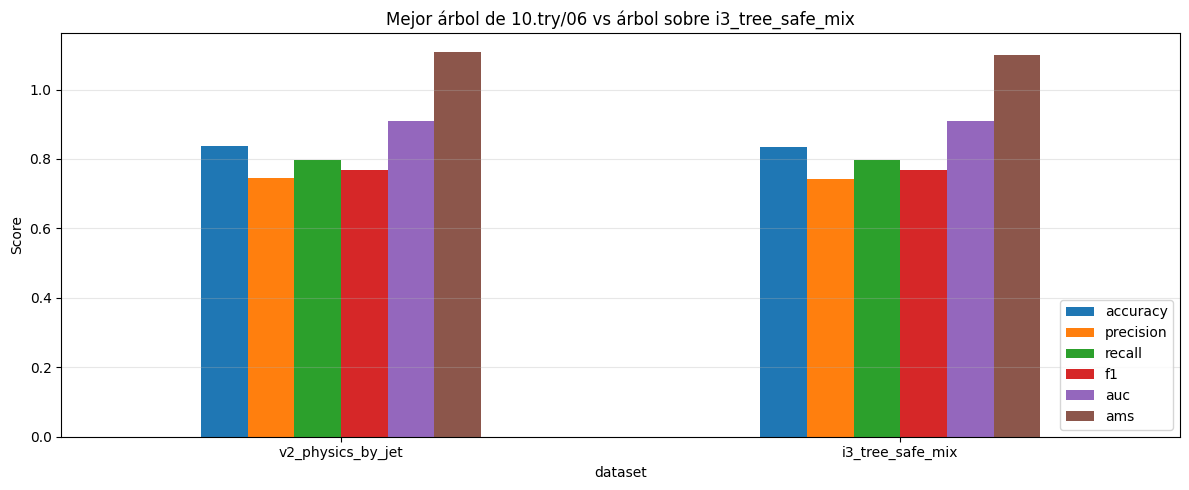

In [5]:
comparison_rows = [
    {
        **reference_tree,
        "fit_seconds": pd.NA,
        "feature_count": pd.NA,
        "train_nan_count": pd.NA,
        "valid_nan_count": pd.NA,
    },
    mix_result,
]
comparison_df = pd.DataFrame(comparison_rows)
reference_row = comparison_df.loc[comparison_df["dataset"] == str(reference_tree["dataset"])].iloc[0]

for metric in ["accuracy", "precision", "recall", "f1", "auc", "ams"]:
    comparison_df[f"delta_{metric}_vs_best_10try06"] = comparison_df[metric].astype("Float64") - float(reference_row[metric])

ordered_columns = [
    "dataset",
    "source",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "auc",
    "ams",
    "ams_threshold",
    "feature_count",
    "train_nan_count",
    "valid_nan_count",
    "fit_seconds",
    "delta_accuracy_vs_best_10try06",
    "delta_precision_vs_best_10try06",
    "delta_recall_vs_best_10try06",
    "delta_f1_vs_best_10try06",
    "delta_auc_vs_best_10try06",
    "delta_ams_vs_best_10try06",
]

print("Comparación contra el mejor árbol de 10.try/06:")
display(comparison_df[ordered_columns].round(4))

plot_df = comparison_df.set_index("dataset")[["accuracy", "precision", "recall", "f1", "auc", "ams"]]
plot_df.plot(kind="bar", figsize=(12, 5), rot=0)
plt.ylabel("Score")
plt.title("Mejor árbol de 10.try/06 vs árbol sobre i3_tree_safe_mix")
plt.grid(axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [6]:
results_dir = dataset["project_root"] / "11.Mezcla" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
comparison_csv_path = results_dir / "i3_tree_safe_mix_vs_best_10try06.csv"
summary_txt_path = results_dir / "i3_tree_safe_mix_vs_best_10try06_summary.txt"

comparison_df.to_csv(comparison_csv_path, index=False)

winner_auc = comparison_df.sort_values("auc", ascending=False).iloc[0]
winner_ams = comparison_df.sort_values("ams", ascending=False).iloc[0]

summary_lines = [
    "# Comparación i3_tree_safe_mix vs mejor árbol de 10.try/06",
    "",
    f"Referencia 10.try/06: {reference_row['dataset']}",
    f"- accuracy={float(reference_row['accuracy']):.6f}",
    f"- precision={float(reference_row['precision']):.6f}",
    f"- recall={float(reference_row['recall']):.6f}",
    f"- f1={float(reference_row['f1']):.6f}",
    f"- auc={float(reference_row['auc']):.6f}",
    f"- ams={float(reference_row['ams']):.6f}",
    "",
    "Resultado sobre i3_tree_safe_mix:",
    f"- accuracy={mix_result['accuracy']:.6f}",
    f"- precision={mix_result['precision']:.6f}",
    f"- recall={mix_result['recall']:.6f}",
    f"- f1={mix_result['f1']:.6f}",
    f"- auc={mix_result['auc']:.6f}",
    f"- ams={mix_result['ams']:.6f}",
    "",
    f"Ganador por AUC: {winner_auc['dataset']} con {winner_auc['auc']:.6f}",
    f"Ganador por AMS: {winner_ams['dataset']} con {winner_ams['ams']:.6f}",
    "",
    f"CSV guardado en: {comparison_csv_path}",
]
summary_txt_path.write_text("\n".join(summary_lines) + "\n")

print(f"CSV comparativo guardado en: {comparison_csv_path}")
print(f"Resumen textual guardado en: {summary_txt_path}")


CSV comparativo guardado en: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/results/i3_tree_safe_mix_vs_best_10try06.csv
Resumen textual guardado en: /home/santig14/fing/taa/1_TallerAA/11.Mezcla/results/i3_tree_safe_mix_vs_best_10try06_summary.txt
